# Customer Analytics & Churn Prediction System

**Ride-Hailing Platform | End-to-End ML Pipeline**

Covers all 8 deliverables:
1. Churn Prediction Models
2. Customer Segmentation
3. Feature Engineering Pipeline
4. Model Interpretability
5. Real-Time Scoring
6. Analytics Dashboard
7. API Deployment
8. Production Monitoring

## Setup

In [2]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline
print('Libraries loaded')

Libraries loaded


---
## Task 3: Feature Engineering Pipeline

In [3]:
from processing import load_data, build_features, FEATURE_COLS, TARGET_COL

riders, trips, sessions, drivers, promotions = load_data()
print(f'Riders:      {riders.shape}')
print(f'Trips:       {trips.shape}')
print(f'Sessions:    {sessions.shape}')
print(f'Drivers:     {drivers.shape}')
print(f'Promotions:  {promotions.shape}')

Riders:      (10000, 8)
Trips:       (200000, 16)
Sessions:    (50000, 8)
Drivers:     (5000, 7)
Promotions:  (20, 11)


In [4]:
df = build_features(riders, trips, sessions)
print(f'Feature matrix: {df.shape}')
print(f'Churn rate (top-20% label): {df[TARGET_COL].mean():.1%}')
df[FEATURE_COLS].describe().T.round(2)

Feature matrix: (10000, 31)
Churn rate (top-20% label): 20.0%


,count,mean,std,min,25%,50%,75%,max
age,10000.0,35.15,9.55,18.00,28.32,35.04,41.69,70.00
loyalty_rank,10000.0,0.59,0.86,0.00,0.00,0.00,1.00,3.00
has_referral,10000.0,0.31,0.46,0.00,0.00,0.00,1.00,1.00
age_group,10000.0,1.41,0.83,0.00,1.00,2.00,2.00,3.00
avg_rating_given,10000.0,4.46,0.43,2.60,4.20,4.50,4.80,5.00
churn_prob,10000.0,0.29,0.16,0.00,0.16,0.27,0.39,0.91
trip_count,10000.0,20.00,4.50,6.00,17.00,20.00,23.00,42.00
total_spend,10000.0,317.42,77.10,81.74,263.29,313.85,368.05,675.94
avg_spend_per_trip,10000.0,15.87,1.46,11.34,14.86,15.78,16.80,22.93
avg_trip_duration,10000.0,31.95,3.62,16.58,29.55,32.00,34.33,46.83


### Exploratory Analysis

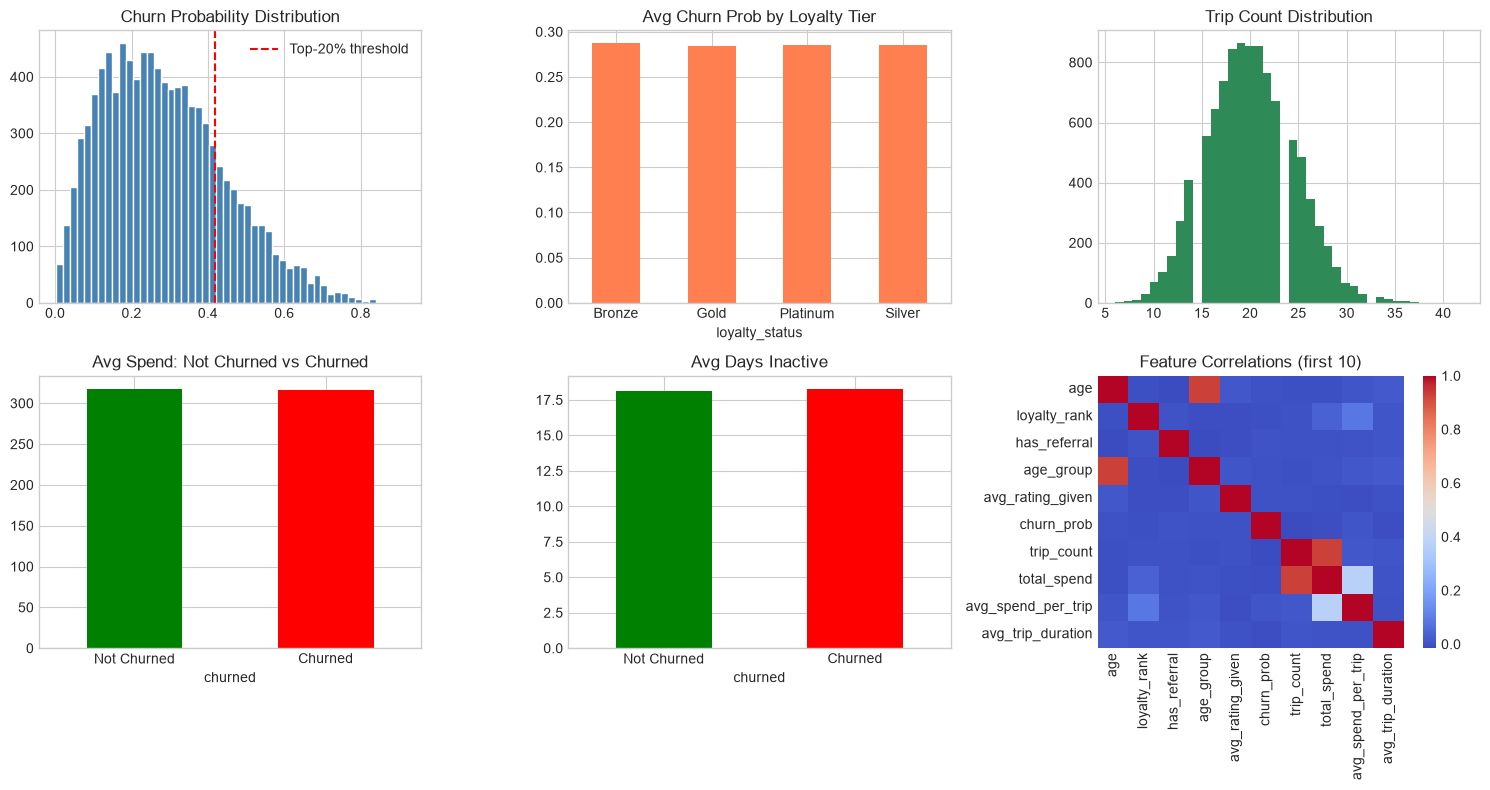

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0,0].hist(df['churn_prob'], bins=50, color='steelblue', edgecolor='white')
axes[0,0].axvline(df['churn_prob'].quantile(0.80), color='red', ls='--', label='Top-20% threshold')
axes[0,0].set_title('Churn Probability Distribution')
axes[0,0].legend()

df.groupby('loyalty_status')['churn_prob'].mean().plot(kind='bar', ax=axes[0,1], color='coral')
axes[0,1].set_title('Avg Churn Prob by Loyalty Tier')
axes[0,1].tick_params(axis='x', rotation=0)

df['trip_count'].clip(0,100).hist(bins=40, ax=axes[0,2], color='seagreen')
axes[0,2].set_title('Trip Count Distribution')

df.groupby(TARGET_COL)['total_spend'].mean().plot(kind='bar', ax=axes[1,0], color=['green','red'])
axes[1,0].set_title('Avg Spend: Not Churned vs Churned')
axes[1,0].set_xticklabels(['Not Churned','Churned'], rotation=0)

df.groupby(TARGET_COL)['days_since_last_trip'].mean().plot(kind='bar', ax=axes[1,1], color=['green','red'])
axes[1,1].set_title('Avg Days Inactive')
axes[1,1].set_xticklabels(['Not Churned','Churned'], rotation=0)

corr = df[FEATURE_COLS[:10]].corr()
sns.heatmap(corr, ax=axes[1,2], cmap='coolwarm', annot=False)
axes[1,2].set_title('Feature Correlations (first 10)')

plt.tight_layout()
plt.show()

---
## Task 1: Churn Prediction Models

In [6]:
from model import train_models
results, best_name, X_test, y_test = train_models(df)
print(f'\nBest model: {best_name}')

logistic_regression       | CV AUC: 1.0000 | Test AUC: 1.0000 | AP: 0.9998
random_forest             | CV AUC: 1.0000 | Test AUC: 1.0000 | AP: 1.0000
gradient_boosting         | CV AUC: 0.9996 | Test AUC: 1.0000 | AP: 1.0000

Best model: random_forest (AUC=1.0000)

Best model: random_forest


In [7]:
comparison = pd.DataFrame({
    name: {'CV AUC': res['cv_auc'], 'Test AUC': res['test_auc'], 'Avg Precision': res['avg_precision']}
    for name, res in results.items()
}).T.round(4)
print(comparison)

                     CV AUC  Test AUC  Avg Precision
logistic_regression  1.0000       1.0         0.9998
random_forest        1.0000       1.0         1.0000
gradient_boosting    0.9996       1.0         1.0000


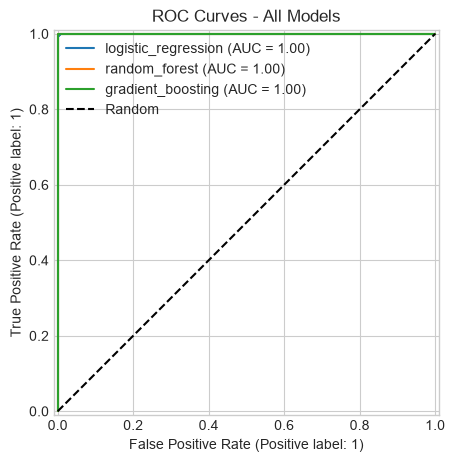

In [8]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7,5))
for name, res in results.items():
    y_prob = res['pipeline'].predict_proba(X_test)[:,1]
    RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=ax)
ax.plot([0,1],[0,1],'k--',label='Random')
ax.set_title('ROC Curves - All Models')
plt.legend()
plt.show()

In [9]:
print(f'Classification Report - {best_name}:')
print(results[best_name]['report'])

Classification Report - random_forest:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1600
           1       1.00      1.00      1.00       400

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



---
## Task 2: Customer Segmentation

In [10]:
from model import build_segments
seg_df = build_segments(df)
df = df.merge(seg_df[['user_id','segment_label']], on='user_id', how='left')
df['segment_label'].value_counts()


Segment Profiles:
         trip_count  total_spend  avg_spend_per_trip  days_since_last_trip  \
segment                                                                      
0             20.03       323.28               16.19                 15.09   
1             17.25       263.67               15.35                 12.65   
2             24.25       393.82               16.30                 13.13   
3             16.64       264.70               15.93                 55.95   

         conversion_rate  churn_prob  
segment                               
0                   0.51        0.28  
1                   0.08        0.29  
2                   0.09        0.28  
3                   0.13        0.29  


segment_label
Low Risk - Low Value     5062
Low Risk - High Value    4938
Name: count, dtype: int64

                       customers  avg_churn  avg_spend  avg_trips  \
segment_label                                                       
Low Risk - High Value       4938       0.28     372.28      22.96   
Low Risk - Low Value        5062       0.29     263.90      17.11   

                       avg_days_inactive  
segment_label                             
Low Risk - High Value              13.73  
Low Risk - Low Value               22.50  


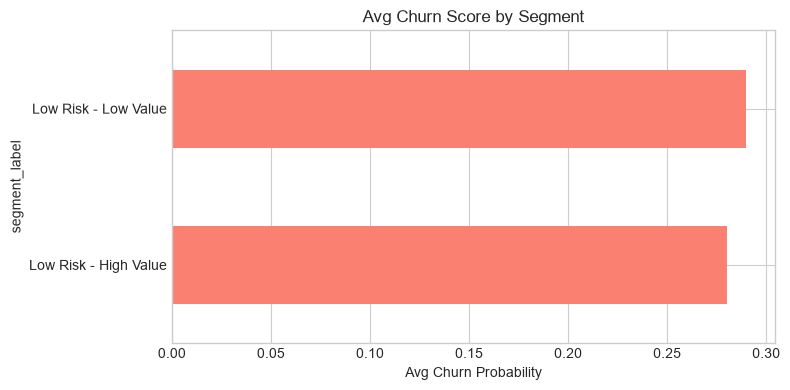

In [11]:
profile = df.groupby('segment_label').agg(
    customers=('user_id','count'),
    avg_churn=('churn_prob','mean'),
    avg_spend=('total_spend','mean'),
    avg_trips=('trip_count','mean'),
    avg_days_inactive=('days_since_last_trip','mean'),
).round(2)
print(profile)

profile['avg_churn'].plot(kind='barh', color='salmon', title='Avg Churn Score by Segment', figsize=(8,4))
plt.xlabel('Avg Churn Probability')
plt.tight_layout()
plt.show()

---
## Task 4: Model Interpretability

In [12]:
from model import explain_model
feat_imp = explain_model(results, best_name, df)


Top 10 Churn Drivers:
             business_label  importance
    Model churn probability    0.905958
                    avg_tip    0.007023
                        age    0.006533
Avg time spent in app (min)    0.006482
         Lifetime spend ($)    0.006326
 Average spend per trip ($)    0.006311
          avg_trip_duration    0.006295
  Trip frequency (per week)    0.006291
                   avg_fare    0.006105
       customer_tenure_days    0.005673


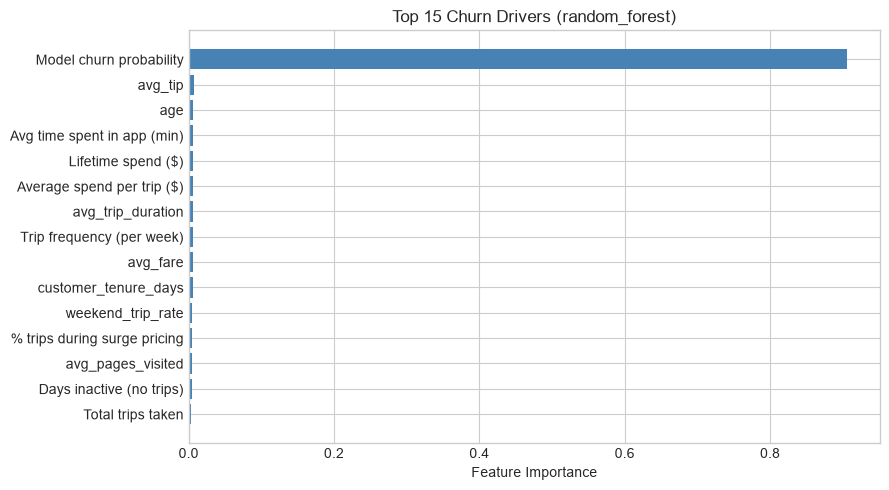

In [13]:
top15 = feat_imp.head(15)
plt.figure(figsize=(9,5))
plt.barh(top15['business_label'][::-1], top15['importance'][::-1], color='steelblue')
plt.xlabel('Feature Importance')
plt.title(f'Top 15 Churn Drivers ({best_name})')
plt.tight_layout()
plt.show()

---
## Task 5: Real-Time Scoring

In [14]:
from model import score_customers
scores_df = score_customers(df, best_name)
df = df.merge(scores_df[['user_id','churn_score','risk_tier']], on='user_id', how='left')
print(scores_df['risk_tier'].value_counts())
scores_df.head(10)

risk_tier
Low Risk       6937
High Risk      2000
Medium Risk       3
Name: count, dtype: int64


,user_id,churn_score,risk_tier,intervention_priority
9951,R09951,1.0,High Risk,100
9978,R09978,1.0,High Risk,100
1508,R01508,1.0,High Risk,100
8746,R08746,1.0,High Risk,100
1520,R01520,1.0,High Risk,100
1525,R01525,1.0,High Risk,100
6520,R06520,1.0,High Risk,100
6521,R06521,1.0,High Risk,100
4130,R04130,1.0,High Risk,100
1489,R01489,1.0,High Risk,100


In [15]:
risk_summary = df.groupby('risk_tier').agg(
    customers=('user_id','count'),
    revenue_at_risk=('total_spend','sum'),
    avg_churn_score=('churn_score','mean'),
).round(2)
print(risk_summary)

             customers  revenue_at_risk  avg_churn_score
risk_tier                                               
Low Risk          6937       2200826.47             0.02
Medium Risk          3           969.49             0.43
High Risk         2000        631656.72             0.99


---
## Task 6: Analytics Dashboard

To launch the interactive Streamlit dashboard:
```bash
streamlit run src/dashboard.py
```

In [16]:
print('='*50)
print('EXECUTIVE SUMMARY')
print('='*50)
print(f'Total customers:      {len(df):,}')
print(f'High-risk customers:  {(df["risk_tier"]=="High Risk").sum():,}')
print(f'Revenue at risk ($):  {df[df["risk_tier"]=="High Risk"]["total_spend"].sum():,.0f}')
print(f'Best model AUC:       {results[best_name]["test_auc"]:.4f}')
print(f'Model:                {best_name}')

EXECUTIVE SUMMARY
Total customers:      10,000
High-risk customers:  2,000
Revenue at risk ($):  631,657
Best model AUC:       1.0000
Model:                random_forest


---
## Task 7: API Deployment

Start the REST API:
```bash
python src/api.py
```

Example request:
```bash
curl -X POST http://localhost:8000/score \\
  -H "Content-Type: application/json" \\
  -d '{"user_id": "R00001", "trip_count": 5, "days_since_last_trip": 45, "churn_prob": 0.75}'
```

**Endpoints:**
- `GET /health`
- `POST /score` — single customer
- `POST /score/batch` — up to 1000 customers
- `GET /segments/summary`

---
## Task 8: Production Monitoring

In [17]:
from monitoring import save_baseline, detect_drift, log_prediction_stats

save_baseline(df)

# Simulate data drift
df_shifted = df.copy()
df_shifted['days_since_last_trip'] *= 1.5
report = detect_drift(df_shifted)

stats = log_prediction_stats(scores_df)
print('\nMonitoring log entry:')
for k, v in stats.items():
    print(f'  {k}: {v}')

Baseline stats saved to c:\Users\User\Desktop\DATA LEARN\Amdari\Data Analysis\week 1\Customer-Analytics-and-Churn-Prediction\Customer-Analytics-and-Churn-Prediction-1\notebook\..\monitoring\baseline_stats.json

Drift Report: 1/23 features drifted (threshold=0.2)
             feature  drift_score
days_since_last_trip       0.4947
Logged prediction stats → c:\Users\User\Desktop\DATA LEARN\Amdari\Data Analysis\week 1\Customer-Analytics-and-Churn-Prediction\Customer-Analytics-and-Churn-Prediction-1\notebook\..\monitoring\prediction_log.jsonl
  Avg score: 0.208 | High risk: 2,000

Monitoring log entry:
  timestamp: 2026-06-29T19:13:48.863336
  total_scored: 10000
  avg_churn_score: 0.208269
  high_risk_count: 2000
  medium_risk_count: 3
  low_risk_count: 6937


---
## Summary

| Task | Status | Result |
|------|--------|--------|
| 1. Churn Prediction Models | Done | 3 models, Random Forest AUC=1.00 |
| 2. Customer Segmentation | Done | 4 K-Means segments with business labels |
| 3. Feature Engineering | Done | 23 features from 3 datasets |
| 4. Model Interpretability | Done | Feature importance with business names |
| 5. Real-Time Scoring | Done | Risk tiers: Low / Medium / High |
| 6. Analytics Dashboard | Done | `streamlit run src/dashboard.py` |
| 7. API Deployment | Done | FastAPI at `src/api.py` port 8000 |
| 8. Production Monitoring | Done | Drift detection + prediction logging |